In [2]:
import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = '/kaggle/input/datasets/pankrzysiu/cifar10-python/cifar-10-batches-py'

def load_batch(file_path):
    with open(file_path, 'rb') as f:
        batch = pickle.load(f, encoding='bytes')

    images = batch[b'data'].reshape(-1, 3, 32, 32)
    images = images.transpose(0, 2, 3, 1)
    labels = np.array(batch[b'labels'])

    return images, labels


x_train, y_train = [], []

for i in range(1, 6):
    images, labels = load_batch(
        os.path.join(DATA_DIR, f'data_batch_{i}')
    )
    x_train.append(images)
    y_train.append(labels)

x_train = np.concatenate(x_train)
y_train = np.concatenate(y_train)

x_test, y_test = load_batch(
    os.path.join(DATA_DIR, 'test_batch')
)

print("Training data:", x_train.shape, y_train.shape)
print("Testing data:", x_test.shape, y_test.shape)
y_train = y_train.flatten()
y_test = y_test.flatten()

indices = []

for i in range(10):
    class_indices = np.where(y_train == i)[0]
    selected = np.random.choice(class_indices, 50, replace=False)
    indices.extend(selected)

x_small = x_train[indices]
y_small = y_train[indices]

print("Selected images:", x_small.shape)
print("Labels:", y_small.shape)

Training data: (50000, 32, 32, 3) (50000,)
Testing data: (10000, 32, 32, 3) (10000,)
Selected images: (500, 32, 32, 3)
Labels: (500,)


In [4]:
from sklearn.model_selection import train_test_split

x_train_small, x_val, y_train_small, y_val = train_test_split(
    x_small,
    y_small,
    test_size=100,
    random_state=42,
    stratify=y_small
)

x_train_small = x_train_small.astype("float32") / 255.0
x_val = x_val.astype("float32") / 255.0
x_test_clean = x_test.astype("float32") / 255.0

print("Training images:", x_train_small.shape)
print("Validation images:", x_val.shape)
print("Clean test images:", x_test_clean.shape)

print("\nTraining class counts:")
print(np.bincount(y_train_small))

print("\nValidation class counts:")
print(np.bincount(y_val))

Training images: (400, 32, 32, 3)
Validation images: (100, 32, 32, 3)
Clean test images: (10000, 32, 32, 3)

Training class counts:
[40 40 40 40 40 40 40 40 40 40]

Validation class counts:
[10 10 10 10 10 10 10 10 10 10]


Shifted test shape: (10000, 32, 32, 3)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


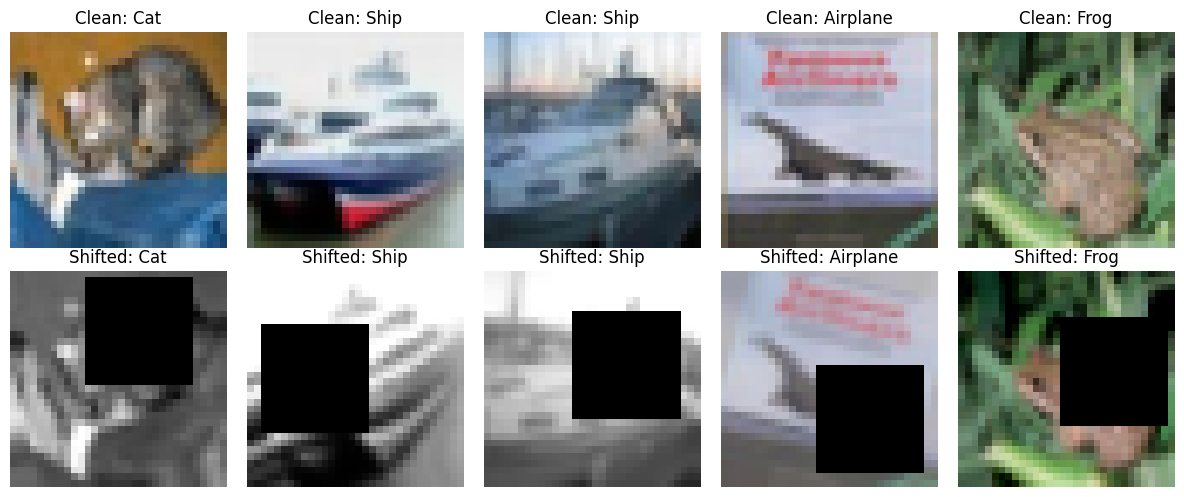

In [5]:
from scipy.ndimage import rotate
rng = np.random.default_rng(42)
x_test_shifted = np.zeros_like(x_test_clean, dtype=np.float32)
for i in range(len(x_test_clean)):
    img = x_test_clean[i].copy()

    angle = rng.uniform(-25, 25)
    img = rotate(
        img,
        angle=angle,
        axes=(1, 0),
        reshape=False,
        order=1,
        mode="nearest"
    )

    brightness = rng.uniform(-0.2, 0.2)
    img = img + brightness

    contrast = rng.uniform(0.7, 1.3)
    mean = np.mean(img, axis=(0, 1), keepdims=True)
    img = (img - mean) * contrast + mean
    img = np.clip(img, 0.0, 1.0)

    y_start = rng.integers(0, 17)
    x_start = rng.integers(0, 17)

    img[y_start:y_start + 16, x_start:x_start + 16, :] = 0.0

    # 5. Hidden corruption  grayscale
    if rng.random() < 0.5:
        gray = np.mean(img, axis=2, keepdims=True)
        img = np.repeat(gray, 3, axis=2)

    x_test_shifted[i] = img

print("Shifted test shape:", x_test_shifted.shape)
print("Minimum pixel value:", x_test_shifted.min())
print("Maximum pixel value:", x_test_shifted.max())

class_names = [
    "Airplane", "Automobile", "Bird", "Cat", "Deer",
    "Dog", "Frog", "Horse", "Ship", "Truck"
]

plt.figure(figsize=(12, 5))

for i in range(5):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test_clean[i])
    plt.title("Clean: " + class_names[y_test[i]])
    plt.axis("off")

    plt.subplot(2, 5, i + 6)
    plt.imshow(x_test_shifted[i])
    plt.title("Shifted: " + class_names[y_test[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [6]:

import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D,
    GlobalAveragePooling2D, Dense, Concatenate
)

def build_baseline_replica():
    inputs = Input(shape=(32, 32, 3))
    x = Conv2D(
        48, (3, 3),
        padding="same",
        activation="relu"
    )(inputs)
    x = MaxPooling2D((2, 2))(x)
    branch1 = Conv2D(
        24, (1, 1),
        padding="same",
        activation="relu"
    )(x)

    branch2 = Conv2D(
        24, (1, 1),
        padding="same",
        activation="relu"
    )(x)

    branch2 = Conv2D(
        24, (3, 3),
        padding="same",
        activation="relu"
    )(branch2)

    branch3 = Conv2D(
        24, (1, 1),
        padding="same",
        activation="relu"
    )(x)

    branch3 = Conv2D(
        24, (5, 5),
        padding="same",
        activation="relu"
    )(branch3)

    x = Concatenate()([branch1, branch2, branch3])
    x = MaxPooling2D((2, 2))(x)
    x = Conv2D(
        48, (3, 3),
        padding="same",
        activation="relu"
    )(x)

    x = GlobalAveragePooling2D()(x)
    x = Dense(128, activation="relu")(x)
    outputs = Dense(10, activation="softmax")(x)
    model = Model(inputs, outputs)
    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


model = build_baseline_replica()

print("Total parameters:", model.count_params())
model.summary()


I0000 00:00:1791690027.148707      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791690027.152020      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Total parameters: 63218


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 32, 32,    │      1,344 │ input_layer[0][0] │
│                     │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 16, 16,    │          0 │ conv2d[0][0]      │
│ (MaxPooling2D)      │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 16, 16,    │      1,176 │ max_pooling2d[0]… │
│                     │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 16, 16,    │      1,176 │ max_pooling2d[0]… │
│                     │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 16, 16,    │      1,176 │ max_pooling2d[0]… │
│                     │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 16, 16,    │      5,208 │ conv2d_2[0][0]    │
│                     │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 16, 16,    │     14,424 │ conv2d_4[0][0]    │
│                     │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 16, 16,    │          0 │ conv2d_1[0][0],   │
│ (Concatenate)       │ 72)               │            │ conv2d_3[0][0],   │
│                     │                   │            │ conv2d_5[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 8, 8, 72)  │          0 │ concatenate[0][0] │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 8, 8, 48)  │     31,152 │ max_pooling2d_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 48)        │          0 │ conv2d_6[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │      6,272 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 10)        │      1,290 │ dense[0][0]       │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 63,218 (246.95 KB)

 Trainable params: 63,218 (246.95 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
import pandas as pd
experiment_seeds = [10, 20, 30]
results = []
histories = {}
for seed in experiment_seeds:
    print("\n" + "=" * 50)
    print(f"EXPERIMENT WITH SEED {seed}")
    print("=" * 50)
    tf.keras.utils.set_random_seed(seed)

    model =build_baseline_replica()
    history = model.fit(
        x_train_small,
        y_train_small,
        validation_data=(x_val, y_val),
        epochs=60,
        batch_size=32,
        shuffle=True,
        verbose=1
    )

    histories[seed] = history.history
    train_acc = history.history["accuracy"][-1]
    val_acc = history.history["val_accuracy"][-1]
    clean_loss, clean_acc = model.evaluate(
        x_test_clean, y_test, verbose=0
    )
    shifted_loss, shifted_acc = model.evaluate(
        x_test_shifted, y_test, verbose=0
    )
    results.append({
        "Seed": seed,
        "Train Accuracy": train_acc,
        "Validation Accuracy": val_acc,
        "Clean Test Accuracy": clean_acc,
        "Shifted Test Accuracy": shifted_acc,
        "Clean Test Loss": clean_loss,
        "Shifted Test Loss": shifted_loss
    })

    print(f"\nSeed: {seed}")
    print(f"Training Accuracy: {train_acc:.4f}")
    print(f"Validation Accuracy: {val_acc:.4f}")
    print(f"Clean Test Accuracy: {clean_acc:.4f}")
    print(f"Shifted Test Accuracy: {shifted_acc:.4f}")



EXPERIMENT WITH SEED 10
Epoch 1/60
 1/13 ━━━━━━━━━━━━━━━━━━━━ 1:08 6s/step - accuracy: 0.0000e+00 - loss: 2.3184

I0000 00:00:1791690034.504540     148 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


13/13 ━━━━━━━━━━━━━━━━━━━━ 10s 350ms/step - accuracy: 0.0700 - loss: 2.3062 - val_accuracy: 0.1000 - val_loss: 2.3005
Epoch 2/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.1275 - loss: 2.2968 - val_accuracy: 0.1600 - val_loss: 2.2859
Epoch 3/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.1350 - loss: 2.2696 - val_accuracy: 0.1300 - val_loss: 2.2414
Epoch 4/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.1125 - loss: 2.1985 - val_accuracy: 0.1800 - val_loss: 2.1307
Epoch 5/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.1775 - loss: 2.1231 - val_accuracy: 0.2100 - val_loss: 2.1122
Epoch 6/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.1775 - loss: 2.0688 - val_accuracy: 0.2200 - val_loss: 2.0811
Epoch 7/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.2000 - loss: 2.0709 - val_accuracy: 0.2100 - val_loss: 2.0735
Epoch 8/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.2300 - loss: 2.0459 - val_accuracy: 0.1800 - val_loss: 

In [8]:
results_df = pd.DataFrame(results)
print("PART A: BASELINE RESULTS")
display(results_df.round(4))
metrics = [
    "Train Accuracy",
    "Validation Accuracy",
    "Clean Test Accuracy",
    "Shifted Test Accuracy"
]
summary_rows = []
for metric in metrics:
    values = results_df[metric].to_numpy()
    summary_rows.append({
        "Metric": metric,
        "Mean": np.mean(values),
        "Std": np.std(values, ddof=1)
    })
summary_df = pd.DataFrame(summary_rows)
print("\nMean ± Standard Deviation across 3 seeds")
display(summary_df.round(4))

PART A: BASELINE RESULTS


,Seed,Train Accuracy,Validation Accuracy,Clean Test Accuracy,Shifted Test Accuracy,Clean Test Loss,Shifted Test Loss
0,10,0.5475,0.40,0.3794,0.1786,1.8154,3.0719
1,20,0.5700,0.42,0.3517,0.1700,1.9956,3.4052
2,30,0.5450,0.38,0.3595,0.1554,1.9165,3.2856



Mean ± Standard Deviation across 3 seeds


,Metric,Mean,Std
0,Train Accuracy,0.5542,0.0138
1,Validation Accuracy,0.4000,0.0200
2,Clean Test Accuracy,0.3635,0.0143
3,Shifted Test Accuracy,0.1680,0.0117


In [9]:

import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D,
    GlobalAveragePooling2D, Dense, Concatenate
)
def inception_block(x, filters):
    b1 = Conv2D(
        filters, (1, 1),
        padding="same", activation="relu"
    )(x)
    b2 = Conv2D(
        filters, (1, 1),
        padding="same", activation="relu"
    )(x)
    b2 = Conv2D(
        filters, (3, 3),
        padding="same", activation="relu"
    )(b2)

    b3 = Conv2D(
        filters, (1, 1),
        padding="same", activation="relu"
    )(x)
    b3 = Conv2D(
        filters, (5, 5),
        padding="same", activation="relu"
    )(b3)
    return Concatenate()([b1, b2, b3])
def build_deeper_inception_model():
    inputs = Input(shape=(32, 32, 3))

    x = Conv2D(
        32, (3, 3),
        padding="same", activation="relu"
    )(inputs)

    x = MaxPooling2D((2, 2))(x)
    x = inception_block(x, 32)
    x = MaxPooling2D((2, 2))(x)
    x = Conv2D(
        64, (3, 3),
        padding="same", activation="relu"
    )(x)

    x = inception_block(x, 32)
    x = Conv2D(
        96, (3, 3),
        padding="same", activation="relu"
    )(x)

    x = GlobalAveragePooling2D()(x)
    x = Dense(96, activation="relu")(x)
    outputs = Dense(10, activation="softmax")(x)
    model = Model(inputs, outputs)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model


model_deeper = build_deeper_inception_model()
print("Total parameters:", model_deeper.count_params())
model_deeper.summary()


Total parameters: 228746


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_28 (Conv2D)  │ (None, 32, 32,    │        896 │ input_layer_4[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_8     │ (None, 16, 16,    │          0 │ conv2d_28[0][0]   │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_30 (Conv2D)  │ (None, 16, 16,    │      1,056 │ max_pooling2d_8[… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_32 (Conv2D)  │ (None, 16, 16,    │      1,056 │ max_pooling2d_8[… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_29 (Conv2D)  │ (None, 16, 16,    │      1,056 │ max_pooling2d_8[… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_31 (Conv2D)  │ (None, 16, 16,    │      9,248 │ conv2d_30[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_33 (Conv2D)  │ (None, 16, 16,    │     25,632 │ conv2d_32[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_4       │ (None, 16, 16,    │          0 │ conv2d_29[0][0],  │
│ (Concatenate)       │ 96)               │            │ conv2d_31[0][0],  │
│                     │                   │            │ conv2d_33[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_9     │ (None, 8, 8, 96)  │          0 │ concatenate_4[0]… │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_34 (Conv2D)  │ (None, 8, 8, 64)  │     55,360 │ max_pooling2d_9[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_36 (Conv2D)  │ (None, 8, 8, 32)  │      2,080 │ conv2d_34[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_38 (Conv2D)  │ (None, 8, 8, 32)  │      2,080 │ conv2d_34[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_35 (Conv2D)  │ (None, 8, 8, 32)  │      2,080 │ conv2d_34[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_37 (Conv2D)  │ (None, 8, 8, 32)  │      9,248 │ conv2d_36[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_39 (Conv2D)  │ (None, 8, 8, 32)  │     25,632 │ conv2d_38[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_5       │ (None, 8, 8, 96)  │          0 │ conv2d_35[0][0],  │
│ (Concatenate)       │                   │            │ conv2d_37[0][0],  │
│                     │                   │            │ conv2d_39[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_40 (Conv2D)  │ (None, 8, 8, 96)  │     83,040 │ concatenate_5[0]… │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 228,746 (893.54 KB)

 Trainable params: 228,746 (893.54 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
import pandas as pd
experiment_seeds = [10, 20, 30]
results = []
histories = {}
for seed in experiment_seeds:
    print("\n" + "=" * 50)
    print(f"EXPERIMENT WITH SEED {seed}")
    print("=" * 50)

    tf.keras.utils.set_random_seed(seed)
    model =build_deeper_inception_model()
    history = model.fit(
        x_train_small,
        y_train_small,
        validation_data=(x_val, y_val),
        epochs=60,
        batch_size=32,
        shuffle=True,
        verbose=1
    )

    histories[seed] = history.history
    train_acc = history.history["accuracy"][-1]
    val_acc = history.history["val_accuracy"][-1]
    clean_loss, clean_acc = model.evaluate(
        x_test_clean, y_test, verbose=0
    )

    shifted_loss, shifted_acc = model.evaluate(
        x_test_shifted, y_test, verbose=0
    )

    results.append({
        "Seed": seed,
        "Train Accuracy": train_acc,
        "Validation Accuracy": val_acc,
        "Clean Test Accuracy": clean_acc,
        "Shifted Test Accuracy": shifted_acc,
        "Clean Test Loss": clean_loss,
        "Shifted Test Loss": shifted_loss
    })

    print(f"\nSeed: {seed}")
    print(f"Training Accuracy: {train_acc:.4f}")
    print(f"Validation Accuracy: {val_acc:.4f}")
    print(f"Clean Test Accuracy: {clean_acc:.4f}")
    print(f"Shifted Test Accuracy: {shifted_acc:.4f}")



EXPERIMENT WITH SEED 10
Epoch 1/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 13s 491ms/step - accuracy: 0.0775 - loss: 2.3066 - val_accuracy: 0.1100 - val_loss: 2.3015
Epoch 2/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.1000 - loss: 2.2965 - val_accuracy: 0.1900 - val_loss: 2.2754
Epoch 3/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.1600 - loss: 2.2387 - val_accuracy: 0.1800 - val_loss: 2.1883
Epoch 4/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.1550 - loss: 2.1722 - val_accuracy: 0.2000 - val_loss: 2.1879
Epoch 5/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.1975 - loss: 2.0851 - val_accuracy: 0.2400 - val_loss: 2.0675
Epoch 6/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.1950 - loss: 2.0645 - val_accuracy: 0.2100 - val_loss: 2.0284
Epoch 7/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.2150 - loss: 1.9969 - val_accuracy: 0.2400 - val_loss: 2.0050
Epoch 8/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.2400 - loss: 1.9474

In [11]:
results_df = pd.DataFrame(results)
print("PART A: BASELINE RESULTS")
display(results_df.round(4))
metrics = [
    "Train Accuracy",
    "Validation Accuracy",
    "Clean Test Accuracy",
    "Shifted Test Accuracy"
]
summary_rows = []
for metric in metrics:
    values = results_df[metric].to_numpy()
    summary_rows.append({
        "Metric": metric,
        "Mean": np.mean(values),
        "Std": np.std(values, ddof=1)
    })
summary_df = pd.DataFrame(summary_rows)
print("\nMean ± Standard Deviation across 3 seeds")
display(summary_df.round(4))

PART A: BASELINE RESULTS


,Seed,Train Accuracy,Validation Accuracy,Clean Test Accuracy,Shifted Test Accuracy,Clean Test Loss,Shifted Test Loss
0,10,0.680,0.33,0.3433,0.1333,2.7063,9.3848
1,20,0.730,0.43,0.3424,0.1882,2.8500,3.7500
2,30,0.795,0.41,0.3476,0.1655,3.1842,4.9541



Mean ± Standard Deviation across 3 seeds


,Metric,Mean,Std
0,Train Accuracy,0.7350,0.0577
1,Validation Accuracy,0.3900,0.0529
2,Clean Test Accuracy,0.3444,0.0028
3,Shifted Test Accuracy,0.1623,0.0276


In [12]:
from tensorflow.keras.models import Model
import tensorflow as tf
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    GlobalAveragePooling2D,
    Dense,
    Concatenate
)
def build_baseline_model():
    inputs = Input(shape=(32, 32, 3))
    x = Conv2D(
        32, (3, 3),
        padding="same",
        activation="relu"
    )(inputs)
    x = MaxPooling2D((2, 2))(x)
    branch1 = Conv2D(
        16, (1, 1),
        padding="same",
        activation="relu"
    )(x)
    branch2 = Conv2D(
        16, (1, 1),
        padding="same",
        activation="relu"
    )(x)
    branch2 = Conv2D(
        16, (3, 3),
        padding="same",
        activation="relu"
    )(branch2)
    branch3 = Conv2D(
        16, (1, 1),
        padding="same",
        activation="relu"
    )(x)
    branch3 = Conv2D(
        16, (5, 5),
        padding="same",
        activation="relu"
    )(branch3)
    x = Concatenate()([branch1, branch2, branch3])
    x = MaxPooling2D((2, 2))(x)
    x = Conv2D(
        32, (3, 3),
        padding="same",
        activation="relu"
    )(x)
    x = GlobalAveragePooling2D()(x)
    x = Dense(64, activation="relu")(x)
    outputs = Dense(10, activation="softmax")(x)
    model = Model(inputs=inputs, outputs=outputs)
    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model


tf.keras.utils.set_random_seed(10)
model_check = build_baseline_model()
model_check.summary()


Model: "functional_8"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_8       │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_80 (Conv2D)  │ (None, 32, 32,    │        896 │ input_layer_8[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_16    │ (None, 16, 16,    │          0 │ conv2d_80[0][0]   │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_82 (Conv2D)  │ (None, 16, 16,    │        528 │ max_pooling2d_16… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_84 (Conv2D)  │ (None, 16, 16,    │        528 │ max_pooling2d_16… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_81 (Conv2D)  │ (None, 16, 16,    │        528 │ max_pooling2d_16… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_83 (Conv2D)  │ (None, 16, 16,    │      2,320 │ conv2d_82[0][0]   │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_85 (Conv2D)  │ (None, 16, 16,    │      6,416 │ conv2d_84[0][0]   │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_12      │ (None, 16, 16,    │          0 │ conv2d_81[0][0],  │
│ (Concatenate)       │ 48)               │            │ conv2d_83[0][0],  │
│                     │                   │            │ conv2d_85[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_17    │ (None, 8, 8, 48)  │          0 │ concatenate_12[0… │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_86 (Conv2D)  │ (None, 8, 8, 32)  │     13,856 │ max_pooling2d_17… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 32)        │          0 │ conv2d_86[0][0]   │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_16 (Dense)    │ (None, 64)        │      2,112 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_17 (Dense)    │ (None, 10)        │        650 │ dense_16[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 27,834 (108.73 KB)

 Trainable params: 27,834 (108.73 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
import pandas as pd
experiment_seeds = [10, 20, 30]
results = []
histories = {}
for seed in experiment_seeds:
    print("\n" + "=" * 50)
    print(f"EXPERIMENT WITH SEED {seed}")
    print("=" * 50)

    tf.keras.utils.set_random_seed(seed)
    model =build_baseline_model()

    history = model.fit(
        x_train_small,
        y_train_small,
        validation_data=(x_val, y_val),
        epochs=60,
        batch_size=32,
        shuffle=True,
        verbose=1
    )

    histories[seed] = history.history
    train_acc = history.history["accuracy"][-1]
    val_acc = history.history["val_accuracy"][-1]

    clean_loss, clean_acc = model.evaluate(
        x_test_clean, y_test, verbose=0
    )

    shifted_loss, shifted_acc = model.evaluate(
        x_test_shifted, y_test, verbose=0
    )

    results.append({
        "Seed": seed,
        "Train Accuracy": train_acc,
        "Validation Accuracy": val_acc,
        "Clean Test Accuracy": clean_acc,
        "Shifted Test Accuracy": shifted_acc,
        "Clean Test Loss": clean_loss,
        "Shifted Test Loss": shifted_loss
    })

    print(f"\nSeed: {seed}")
    print(f"Training Accuracy: {train_acc:.4f}")
    print(f"Validation Accuracy: {val_acc:.4f}")
    print(f"Clean Test Accuracy: {clean_acc:.4f}")
    print(f"Shifted Test Accuracy: {shifted_acc:.4f}")



EXPERIMENT WITH SEED 10
Epoch 1/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 8s 314ms/step - accuracy: 0.1050 - loss: 2.3055 - val_accuracy: 0.1100 - val_loss: 2.3012
Epoch 2/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.1175 - loss: 2.3007 - val_accuracy: 0.1000 - val_loss: 2.2988
Epoch 3/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.1025 - loss: 2.2967 - val_accuracy: 0.1000 - val_loss: 2.2916
Epoch 4/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.1225 - loss: 2.2856 - val_accuracy: 0.1500 - val_loss: 2.2727
Epoch 5/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.1400 - loss: 2.2561 - val_accuracy: 0.2300 - val_loss: 2.2165
Epoch 6/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.1925 - loss: 2.1808 - val_accuracy: 0.2000 - val_loss: 2.1335
Epoch 7/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.1950 - loss: 2.1237 - val_accuracy: 0.2400 - val_loss: 2.0708
Epoch 8/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.2550 - loss: 2.0237 

In [14]:
results_df = pd.DataFrame(results)

print("PART A: BASELINE RESULTS")
display(results_df.round(4))

metrics = [
    "Train Accuracy",
    "Validation Accuracy",
    "Clean Test Accuracy",
    "Shifted Test Accuracy"
]

summary_rows = []

for metric in metrics:
    values = results_df[metric].to_numpy()

    summary_rows.append({
        "Metric": metric,
        "Mean": np.mean(values),
        "Std": np.std(values, ddof=1)
    })

summary_df = pd.DataFrame(summary_rows)

print("\nMean ± Standard Deviation across 3 seeds")
display(summary_df.round(4))

PART A: BASELINE RESULTS


,Seed,Train Accuracy,Validation Accuracy,Clean Test Accuracy,Shifted Test Accuracy,Clean Test Loss,Shifted Test Loss
0,10,0.44,0.38,0.3462,0.1578,1.7935,3.0819
1,20,0.49,0.31,0.3301,0.1768,1.9541,3.0955
2,30,0.49,0.29,0.3364,0.1789,1.8989,2.5516



Mean ± Standard Deviation across 3 seeds


,Metric,Mean,Std
0,Train Accuracy,0.4733,0.0289
1,Validation Accuracy,0.3267,0.0473
2,Clean Test Accuracy,0.3376,0.0081
3,Shifted Test Accuracy,0.1712,0.0116


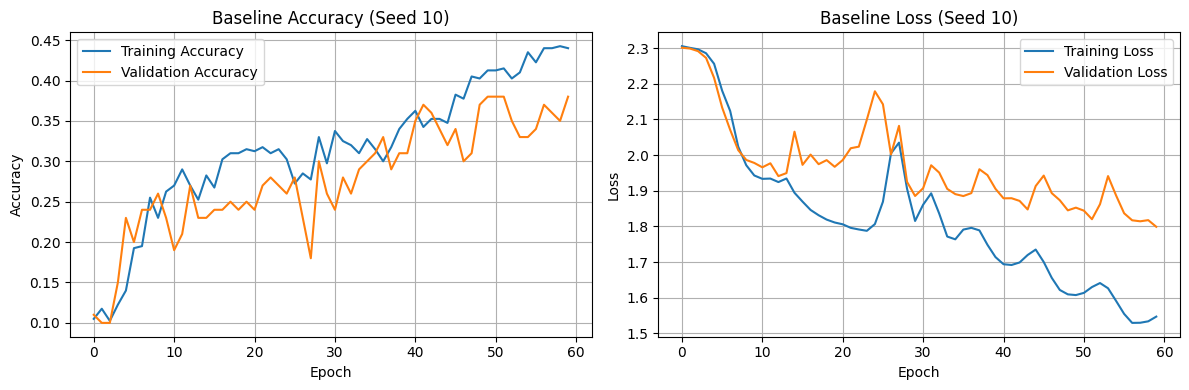

In [15]:
history = histories[10]
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history["accuracy"], label="Training Accuracy")
plt.plot(history["val_accuracy"], label="Validation Accuracy")
plt.title("Baseline Accuracy (Seed 10)")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.subplot(1, 2, 2)
plt.plot(history["loss"], label="Training Loss")
plt.plot(history["val_loss"], label="Validation Loss")
plt.title("Baseline Loss (Seed 10)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Interpretation

- **28K Model:** Achieved 33.76% clean-test and 17.12% shifted-test accuracy. It is lightweight and showed the best shifted-test performance.
- **64K Model:** Achieved the highest validation accuracy (40.00%) and clean-test accuracy (36.35%), providing the best overall balance.
- **228K Model:** Achieved lower test performance despite higher training accuracy, indicating possible overfitting.

**Conclusion:** The 64K model was selected as the baseline for further experiments because it provides the best overall performance with moderate complexity.

**Part A: Baseline Model Analysis**

The baseline Inception-style CNN with approximately **64K parameters** was trained on 400 CIFAR-10 images without data augmentation and evaluated using a 100-image validation set and the clean and simulated shifted test sets. Across three experiments with random seeds 10, 20, and 30, the model achieved a mean clean-test accuracy of **36.35%** and a mean shifted-test accuracy of **16.80%**. The **19.55 percentage-point performance drop** indicates that the baseline is sensitive to simulated image corruptions, suggesting limited robustness to distribution shifts. The mean training accuracy (55.42%) is higher than the mean validation accuracy (40.00%), suggesting possible overfitting and limited generalization to unseen images.

# PART B

In [16]:
import tensorflow as tf
from tensorflow.keras import layers, Sequential

geometric_augmentation = Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(
        factor=25/360,
        fill_mode="reflect",
        seed=42
    ),
    layers.RandomTranslation(
        height_factor=0.10,
        width_factor=0.10,
        fill_mode="reflect",
        seed=42
    )
], name="geometric_augmentation")


photometric_augmentation = Sequential([
    layers.RandomBrightness(
        factor=0.15,
        value_range=(0, 1),
        seed=42
    ),
    layers.RandomContrast(
        factor=0.20,
        seed=42
    )
], name="photometric_augmentation")

combined_augmentation = Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(
        factor=25/360,
        fill_mode="reflect",
        seed=42
    ),
    layers.RandomTranslation(
        height_factor=0.10,
        width_factor=0.10,
        fill_mode="reflect",
        seed=42
    ),
    layers.RandomBrightness(
        factor=0.15,
        value_range=(0, 1),
        seed=42
    ),
    layers.RandomContrast(
        factor=0.20,
        seed=42
    )
], name="combined_augmentation")

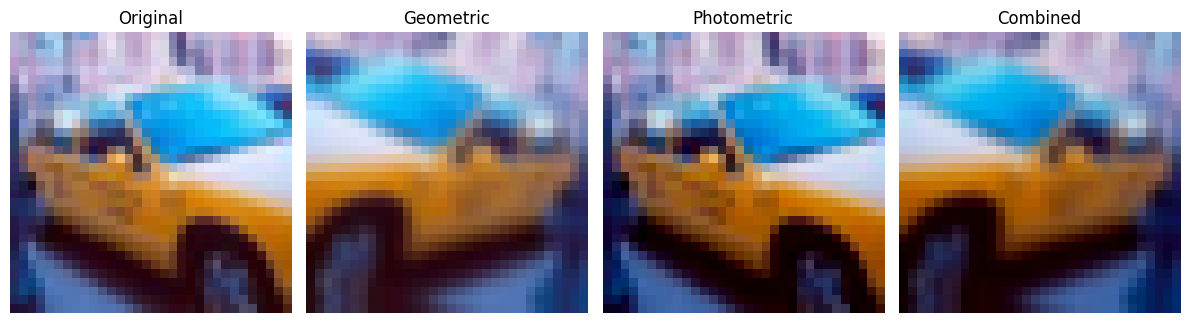

In [17]:
sample_image = x_train_small[0:1]
augmentations = [
    ("Original", None),
    ("Geometric", geometric_augmentation),
    ("Photometric", photometric_augmentation),
    ("Combined", combined_augmentation)
]
plt.figure(figsize=(12, 4))
for i, (name, augmentation) in enumerate(augmentations):
    if augmentation is None:
        image = sample_image[0]
    else:
        image = augmentation(sample_image, training=True)[0].numpy()
        image = tf.clip_by_value(image, 0, 1).numpy()
    plt.subplot(1, 4, i + 1)
    plt.imshow(image)
    plt.title(name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [20]:

from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D,
    GlobalAveragePooling2D, Dense, Concatenate
)

def build_augmented_model(augmentation=None):
    inputs = Input(shape=(32, 32, 3))

    if augmentation is not None:
        x = augmentation(inputs)
    else:
        x = inputs

    x = Conv2D(
        48, (3, 3),
        padding="same",
        activation="relu"
    )(x)

    x = MaxPooling2D((2, 2))(x)

    branch1 = Conv2D(
        24, (1, 1),
        padding="same",
        activation="relu"
    )(x)

    branch2 = Conv2D(
        24, (1, 1),
        padding="same",
        activation="relu"
    )(x)

    branch2 = Conv2D(
        24, (3, 3),
        padding="same",
        activation="relu"
    )(branch2)

    branch3 = Conv2D(
        24, (1, 1),
        padding="same",
        activation="relu"
    )(x)

    branch3 = Conv2D(
        24, (5, 5),
        padding="same",
        activation="relu"
    )(branch3)

    x = Concatenate()([branch1, branch2, branch3])

    x = MaxPooling2D((2, 2))(x)

    x = Conv2D(
        48, (3, 3),
        padding="same",
        activation="relu"
    )(x)

    x = GlobalAveragePooling2D()(x)

    x = Dense(128, activation="relu")(x)

    outputs = Dense(10, activation="softmax")(x)

    model = Model(inputs, outputs)

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


experiment_seeds = [10, 20, 30]

augmentation_experiments = {
    "Geometric": geometric_augmentation,
    "Photometric": photometric_augmentation,
    "Combined": combined_augmentation
}

part_b_results = []

for aug_name, augmentation in augmentation_experiments.items():

    print(f"\n{'='*50}")
    print(f"Experiment: {aug_name}")
    print(f"{'='*50}")

    for seed in experiment_seeds:

        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(seed)

        model = build_augmented_model(augmentation)

        history = model.fit(
            x_train_small,
            y_train_small,
            validation_data=(x_val, y_val),
            epochs=60,
            batch_size=32,
            shuffle=True,
            verbose=1
        )

        train_loss, train_acc = model.evaluate(
            x_train_small, y_train_small, verbose=0
        )

        val_loss, val_acc = model.evaluate(
            x_val, y_val, verbose=0
        )

        clean_loss, clean_acc = model.evaluate(
            x_test_clean, y_test, verbose=0
        )

        shifted_loss, shifted_acc = model.evaluate(
            x_test_shifted, y_test, verbose=0
        )

        part_b_results.append({
            "Augmentation": aug_name,
            "Seed": seed,
            "Train Accuracy": train_acc,
            "Validation Accuracy": val_acc,
            "Clean Test Accuracy": clean_acc,
            "Shifted Test Accuracy": shifted_acc
        })

        print(
            f"Seed {seed} | "
            f"Val: {val_acc:.4f} | "
            f"Clean: {clean_acc:.4f} | "
            f"Shifted: {shifted_acc:.4f}"
        )



Experiment: Geometric
Epoch 1/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 58ms/step - accuracy: 0.0775 - loss: 2.3057 - val_accuracy: 0.1100 - val_loss: 2.2984
Epoch 2/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.1275 - loss: 2.2950 - val_accuracy: 0.1700 - val_loss: 2.2808
Epoch 3/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.1325 - loss: 2.2665 - val_accuracy: 0.1300 - val_loss: 2.2384
Epoch 4/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.1075 - loss: 2.2029 - val_accuracy: 0.1600 - val_loss: 2.1397
Epoch 5/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.1700 - loss: 2.1203 - val_accuracy: 0.2200 - val_loss: 2.0818
Epoch 6/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.1750 - loss: 2.1116 - val_accuracy: 0.1700 - val_loss: 2.1259
Epoch 7/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.1725 - loss: 2.0815 - val_accuracy: 0.2100 - val_loss: 2.1784
Epoch 8/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.1950 - loss: 2.0870 - v

In [21]:
import pandas as pd
part_b_df = pd.DataFrame(part_b_results)
display(
    part_b_df.round(4)
)

,Augmentation,Seed,Train Accuracy,Validation Accuracy,Clean Test Accuracy,Shifted Test Accuracy
0,Geometric,10,0.3475,0.31,0.2952,0.1853
1,Geometric,20,0.4800,0.41,0.3306,0.1771
2,Geometric,30,0.5175,0.38,0.3674,0.2064
3,Photometric,10,0.5625,0.35,0.3555,0.2310
4,Photometric,20,0.5175,0.32,0.3596,0.2075
5,Photometric,30,0.6275,0.39,0.3747,0.2160
6,Combined,10,0.4750,0.39,0.3558,0.2313
7,Combined,20,0.4150,0.33,0.3189,0.1890
8,Combined,30,0.4600,0.38,0.3531,0.2185


In [22]:
part_b_summary = part_b_df.groupby("Augmentation").agg({
    "Train Accuracy": ["mean", "std"],
    "Validation Accuracy": ["mean", "std"],
    "Clean Test Accuracy": ["mean", "std"],
    "Shifted Test Accuracy": ["mean", "std"]
})

display(part_b_summary.round(4))

Train Accuracy         Validation Accuracy          \
                       mean     std                mean     std   
Augmentation                                                      
Combined             0.4500  0.0312              0.3667  0.0321   
Geometric            0.4483  0.0893              0.3667  0.0513   
Photometric          0.5692  0.0553              0.3533  0.0351   

             Clean Test Accuracy         Shifted Test Accuracy          
                            mean     std                  mean     std  
Augmentation                                                            
Combined                  0.3426  0.0206                0.2129  0.0217  
Geometric                 0.3311  0.0361                0.1896  0.0151  
Photometric               0.3633  0.0101                0.2182  0.0119

### Part B: Answers to the Questions

1\. Would vertical flip help or hurt on this dataset? Why?

Vertical flipping would generally hurt performance or provide limited benefit on CIFAR-10 because most objects have meaningful upright orientations. For example, vertically flipped cars, airplanes, and animals may look unrealistic. These transformations can confuse the model and make it harder to learn useful features. Therefore, horizontal flipping is generally preferred because it increases training diversity while preserving the identity of most objects.

2\. If you augment with rotation up to ±90° but the test only has ±25°, what is the trade-off?

Rotating images up to ±90° may improve recognition of objects in extreme orientations, but it can also generate unrealistic training examples that do not match the test distribution. Since the shifted test set contains rotations of only up to ±25°, moderate rotations are more relevant to the expected test conditions. Larger rotations may make learning more difficult and reduce clean-test accuracy. Therefore, augmentation strength should be selected according to the expected image variations and evaluated experimentally.

3\. Why can too much augmentation reduce accuracy on such a small model?

Excessive augmentation can distort important visual features or create unrealistic images. Since the model is trained on only 400 images and has limited capacity, overly strong transformations can make the learning task unnecessarily difficult. This may cause underfitting, prevent the model from learning useful class-specific features, and reduce clean-test accuracy. Therefore, moderate and realistic augmentation is preferable, and its effectiveness should be evaluated using validation and shifted-test performance.

#  PART C

In [23]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, Model, regularizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.utils import to_categorical

y_train_onehot = to_categorical(y_train_small, num_classes=10)
y_val_onehot = to_categorical(y_val, num_classes=10)
y_test_onehot = to_categorical(y_test, num_classes=10)

print("Training images:", x_train_small.shape)
print("Validation images:", x_val.shape)
print("Clean test images:", x_test_clean.shape)
print("Shifted test images:", x_test_shifted.shape)

Training images: (400, 32, 32, 3)
Validation images: (100, 32, 32, 3)
Clean test images: (10000, 32, 32, 3)
Shifted test images: (10000, 32, 32, 3)


In [26]:
def conv_bn_relu(x, filters, kernel_size, l2_value=1e-4):
    x = layers.Conv2D(
        filters,
        kernel_size,
        padding="same",
        use_bias=False,
        kernel_regularizer=regularizers.l2(l2_value)
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    return x


def build_regularized_model():

    inputs = layers.Input(shape=(32, 32, 3))

    # Photometric augmentation: training images only
    x = layers.RandomBrightness(
        factor=0.15,
        value_range=(0, 1)
    )(inputs)

    x = layers.RandomContrast(factor=0.20)(x)

    x = conv_bn_relu(x, 48, (3, 3))
    x = layers.MaxPooling2D((2, 2))(x)

    branch1 = conv_bn_relu(x, 24, (1, 1))

    branch2 = conv_bn_relu(x, 24, (1, 1))
    branch2 = conv_bn_relu(branch2, 16, (3, 3))

    branch3 = conv_bn_relu(x, 24, (1, 1))
    branch3 = conv_bn_relu(branch3, 24, (5, 5))

    x = layers.Concatenate()([branch1, branch2, branch3])

    x = layers.MaxPooling2D((2, 2))(x)
    x = conv_bn_relu(x, 48, (3, 3))

    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dense(
        128,
        activation="relu",
        kernel_regularizer=regularizers.l2(1e-4)
    )(x)

    x = layers.Dropout(0.30)(x)

    outputs = layers.Dense(
        10,
        activation="softmax",
        kernel_regularizer=regularizers.l2(1e-4)
    )(x)

    model = Model(inputs, outputs)

    optimizer = tf.keras.optimizers.Adam(
        learning_rate=0.001
    )

    loss_fn = tf.keras.losses.CategoricalCrossentropy(
        label_smoothing=0.05
    )

    model.compile(
        optimizer=optimizer,
        loss=loss_fn,
        metrics=["categorical_accuracy"]
    )

    return model

In [27]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    verbose=1
)

lr_scheduler = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

In [28]:
experiment_seeds = [10, 20, 30]

part_c_results = []
part_c_histories = {}

for seed in experiment_seeds:

    print(f"\nTraining with seed {seed}")

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)

    model = build_regularized_model()

    history = model.fit(
        x_train_small,
        y_train_onehot,
        validation_data=(x_val, y_val_onehot),
        epochs=60,
        batch_size=32,
        shuffle=True,
        callbacks=[early_stopping, lr_scheduler],
        verbose=1
    )

    part_c_histories[seed] = history.history

    train_loss, train_acc = model.evaluate(
        x_train_small, y_train_onehot, verbose=0
    )

    val_loss, val_acc = model.evaluate(
        x_val, y_val_onehot, verbose=0
    )

    clean_loss, clean_acc = model.evaluate(
        x_test_clean, y_test_onehot, verbose=0
    )

    shifted_loss, shifted_acc = model.evaluate(
        x_test_shifted, y_test_onehot, verbose=0
    )

    part_c_results.append({
        "Seed": seed,
        "Epochs Trained": len(history.history["loss"]),
        "Train Accuracy": train_acc,
        "Validation Accuracy": val_acc,
        "Clean Test Accuracy": clean_acc,
        "Shifted Test Accuracy": shifted_acc,
        "Trainable Parameters": model.count_params()
    })

    print(
        f"Validation: {val_acc:.4f} | "
        f"Clean: {clean_acc:.4f} | "
        f"Shifted: {shifted_acc:.4f}"
    )


Training with seed 10
Epoch 1/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 16s 630ms/step - categorical_accuracy: 0.1375 - loss: 2.3534 - val_categorical_accuracy: 0.1000 - val_loss: 2.3294 - learning_rate: 0.0010
Epoch 2/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - categorical_accuracy: 0.2225 - loss: 2.1881 - val_categorical_accuracy: 0.1200 - val_loss: 2.3241 - learning_rate: 0.0010
Epoch 3/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - categorical_accuracy: 0.2350 - loss: 2.1063 - val_categorical_accuracy: 0.1200 - val_loss: 2.3267 - learning_rate: 0.0010
Epoch 4/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - categorical_accuracy: 0.2675 - loss: 2.0364 - val_categorical_accuracy: 0.1100 - val_loss: 2.3316 - learning_rate: 0.0010
Epoch 5/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - categorical_accuracy: 0.3191 - loss: 2.0233 
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - categorical_accuracy: 0.3075 - loss: 1.9754 - val_categorica

In [29]:
import pandas as pd

part_c_df = pd.DataFrame(part_c_results)
display(part_c_df.round(4))

metric_columns = [
    "Train Accuracy",
    "Validation Accuracy",
    "Clean Test Accuracy",
    "Shifted Test Accuracy"
]

part_c_summary = part_c_df[metric_columns].agg(["mean", "std"]).T

display(part_c_summary.round(4))

,Seed,Epochs Trained,Train Accuracy,Validation Accuracy,Clean Test Accuracy,Shifted Test Accuracy,Trainable Parameters
0,10,10,0.1225,0.12,0.1280,0.1284,58650
1,20,11,0.1150,0.14,0.1330,0.1030,58650
2,30,8,0.1050,0.11,0.1086,0.1102,58650


,mean,std
Train Accuracy,0.1142,0.0088
Validation Accuracy,0.1233,0.0153
Clean Test Accuracy,0.1232,0.0129
Shifted Test Accuracy,0.1139,0.0131


In [38]:
print("Training image range:",
      x_train_small.min(), x_train_small.max())

print("Validation image range:",
      x_val.min(), x_val.max())

print("Clean test image range:",
      x_test_clean.min(), x_test_clean.max())

print("\nTraining labels:")
print("One-hot shape:", y_train_onehot.shape)
print("Unique label values:", np.unique(y_train_onehot))
print("Class counts:", np.sum(y_train_onehot, axis=0))

for seed, h in part_c_histories.items():
    print(f"\nSeed {seed}")
    print("Epochs:", len(h["loss"]))
    print("First training loss:", round(h["loss"][0], 4))
    print("Last training loss:", round(h["loss"][-1], 4))
    print("Best validation accuracy:",
          round(max(h["val_categorical_accuracy"]) * 100, 2), "%")

Training image range: 0.0 1.0
Validation image range: 0.0 1.0
Clean test image range: 0.0 1.0

Training labels:
One-hot shape: (400, 10)
Unique label values: [0. 1.]
Class counts: [40. 40. 40. 40. 40. 40. 40. 40. 40. 40.]

Seed 10
Epochs: 10
First training loss: 2.3534
Last training loss: 1.7717
Best validation accuracy: 17.0 %

Seed 20
Epochs: 11
First training loss: 2.2899
Last training loss: 1.7285
Best validation accuracy: 14.0 %

Seed 30
Epochs: 8
First training loss: 2.3
Last training loss: 1.8297
Best validation accuracy: 18.0 %


## Part D: Ablation Study

### Results

| Configuration | Validation Accuracy (Mean ± Std) | Clean Test Accuracy (Mean ± Std) | Shifted Test Accuracy (Mean ± Std) |
|---|---:|---:|---:|
| No augmentation | 40.00% ± 2.00% | 36.35% ± 1.43% | 16.80% ± 1.17% |
| Geometric only | 36.67% ± 5.13% | 33.11% ± 3.61% | 18.96% ± 1.51% |
| Photometric only | 35.33% ± 3.51% | 36.33% ± 1.01% | 21.82% ± 1.19% |
| Geometric + photometric | 36.67% ± 3.21% | 34.26% ± 2.06% | 21.29% ± 2.17% |

### Interpretation

Photometric augmentation achieved the highest shifted-test accuracy of **21.82%**, improving performance by **5.02 percentage points** compared with the no-augmentation baseline. This improvement is likely because brightness and contrast augmentation matches similar corruptions in the shifted-test dataset. Combining geometric and photometric augmentation also improved shifted-test accuracy, reaching 21.29%, but did not outperform photometric augmentation alone. Therefore, photometric augmentation was the most effective strategy among the configurations tested so far.

# PART E

In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

# Convert actual labels to class IDs
y_true = np.asarray(y_test)
if y_true.ndim > 1 and y_true.shape[-1] == 10:
    y_true = np.argmax(y_true, axis=1)
else:
    y_true = y_true.reshape(-1)

# Predict clean test images
pred_probs = model.predict(x_test_clean, verbose=0)
y_pred = np.argmax(pred_probs, axis=1)

# Confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=np.arange(10))

# Per-class accuracy
correct = np.diag(cm)
total = cm.sum(axis=1)
accuracy = 100 * correct / np.maximum(total, 1)

results = pd.DataFrame({
    "Class": class_names,
    "Correct Predictions": correct,
    "Total Images": total,
    "Accuracy (%)": np.round(accuracy, 2)
})

display(results)
print("Overall clean accuracy:", round(np.mean(y_true == y_pred) * 100, 2), "%")

,Class,Correct Predictions,Total Images,Accuracy (%)
0,airplane,986,1000,98.6
1,automobile,0,1000,0.0
2,bird,0,1000,0.0
3,cat,100,1000,10.0
4,deer,0,1000,0.0
5,dog,0,1000,0.0
6,frog,0,1000,0.0
7,horse,0,1000,0.0
8,ship,0,1000,0.0
9,truck,0,1000,0.0


Overall clean accuracy: 10.86 %


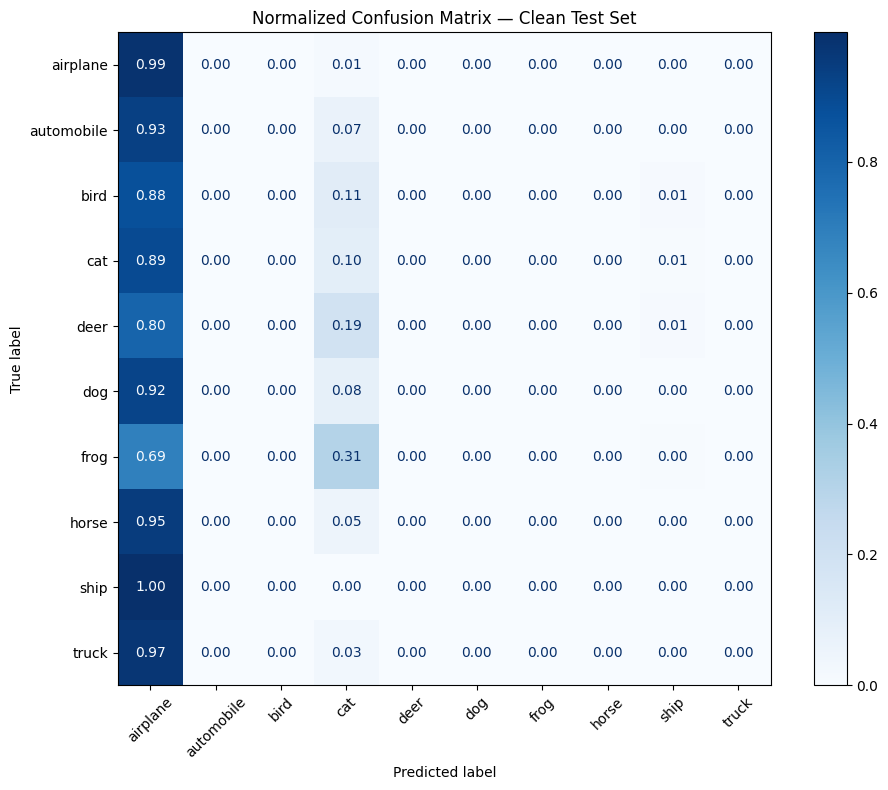

In [40]:
cm_normalized = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)

fig, ax = plt.subplots(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_normalized,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format=".2f",
    xticks_rotation=45
)

ax.set_title("Normalized Confusion Matrix — Clean Test Set")
plt.tight_layout()
plt.show()

In [41]:
cm_errors = cm.copy()
np.fill_diagonal(cm_errors, 0)

pairs = []

for actual in range(10):
    for predicted in range(10):
        if cm_errors[actual, predicted] > 0:
            pairs.append({
                "Actual Class": class_names[actual],
                "Predicted Class": class_names[predicted],
                "Misclassified Images": cm_errors[actual, predicted]
            })

pairs_df = pd.DataFrame(pairs)

if not pairs_df.empty:
    display(
        pairs_df.sort_values(
            "Misclassified Images", ascending=False
        ).head(10)
    )
else:
    print("No misclassified images.")

,Actual Class,Predicted Class,Misclassified Images
22,ship,airplane,998
24,truck,airplane,971
19,horse,airplane,949
1,automobile,airplane,932
13,dog,airplane,917
8,cat,airplane,894
5,bird,airplane,877
10,deer,airplane,796
16,frog,airplane,690
17,frog,cat,306


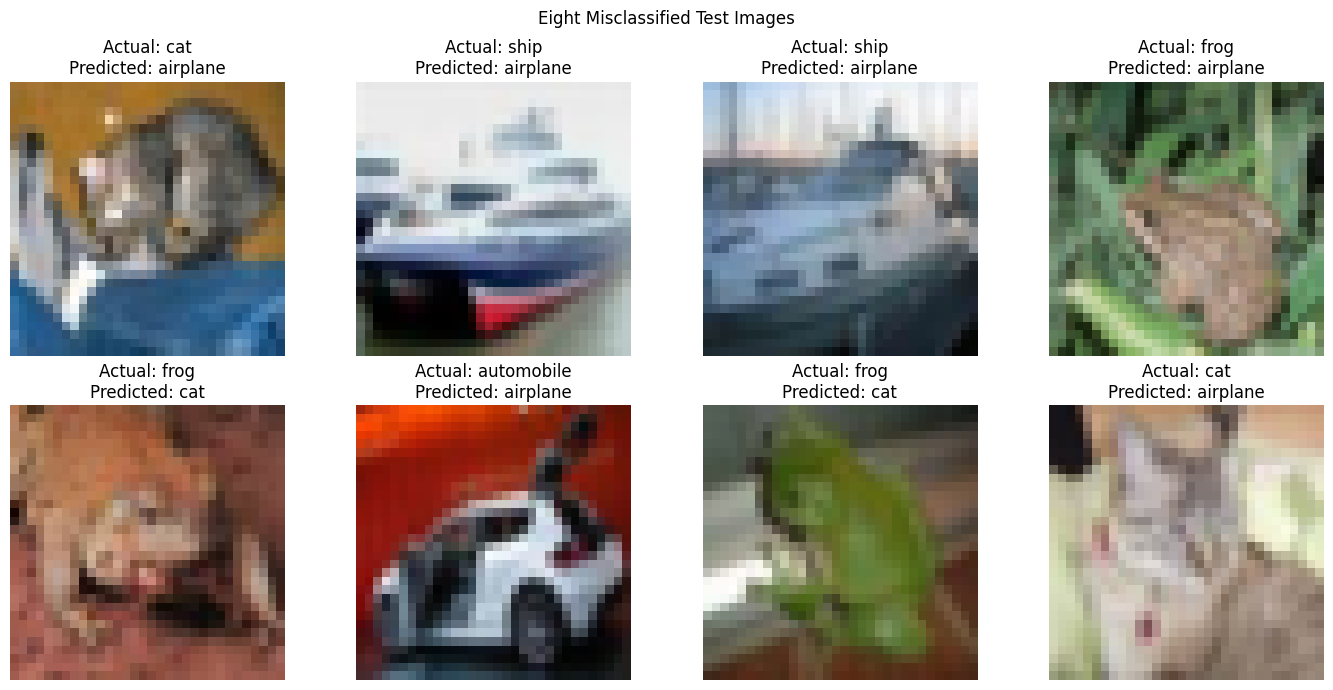

In [42]:
wrong_indices = np.where(y_true != y_pred)[0]

if len(wrong_indices) == 0:
    print("No misclassified images.")
else:
    selected = wrong_indices[:8]

    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    axes = axes.flatten()

    for i, ax in enumerate(axes):
        if i < len(selected):
            idx = selected[i]
            ax.imshow(np.clip(x_test_clean[idx], 0, 1))
            ax.set_title(
                f"Actual: {class_names[y_true[idx]]}\n"
                f"Predicted: {class_names[y_pred[idx]]}"
            )
        ax.axis("off")

    plt.suptitle("Eight Misclassified Test Images")
    plt.tight_layout()
    plt.show()

In [43]:
rng = np.random.default_rng(2026)

x_hidden = x_test_clean.copy()
gray_mask = rng.random(len(x_hidden)) < 0.5

gray = (
    0.299 * x_hidden[..., 0]
    + 0.587 * x_hidden[..., 1]
    + 0.114 * x_hidden[..., 2]
)

x_hidden[gray_mask] = np.repeat(
    gray[gray_mask][..., np.newaxis],
    3,
    axis=-1
)

hidden_probs = model.predict(x_hidden, verbose=0)
hidden_pred = np.argmax(hidden_probs, axis=1)

clean_accuracy = np.mean(y_pred == y_true) * 100
mixed_accuracy = np.mean(hidden_pred == y_true) * 100
gray_accuracy = np.mean(hidden_pred[gray_mask] == y_true[gray_mask]) * 100

print(f"Clean accuracy: {clean_accuracy:.2f}%")
print(f"Mixed accuracy (50% grayscale): {mixed_accuracy:.2f}%")
print(f"Grayscale-only accuracy: {gray_accuracy:.2f}%")
print(f"Grayscale images: {gray_mask.sum()}")

Clean accuracy: 10.86%
Mixed accuracy (50% grayscale): 10.42%
Grayscale-only accuracy: 9.65%
Grayscale images: 4935


# Part E — Evaluation and Error Analysis

The model achieved **10.86% clean-test accuracy**, showing poor classification performance across CIFAR-10 classes. The confusion matrix indicates a strong bias toward predicting airplanes, while the eight misclassified examples demonstrate difficulty distinguishing different objects.

For hidden-corruption evaluation, clean accuracy was **10.86%**, mixed accuracy with 50% grayscale images was **10.42%**, and grayscale-only accuracy was **9.65%**. These results show a slight performance decrease under grayscale conversion. However, the low clean accuracy means the model cannot yet be considered robust to image corruption.

Overall, the model requires improved training and classification performance before reliable robustness conclusions can be drawn.

In [45]:
import numpy as np
import tensorflow as tf
import time

# 1. Baseline: normal prediction on shifted test images
start = time.perf_counter()
baseline_probs = model.predict(x_test_shifted, batch_size=128, verbose=0)
baseline_time = time.perf_counter() - start

baseline_pred = np.argmax(baseline_probs, axis=1)

# Convert labels to class IDs
y_true_f = np.asarray(y_test)
if y_true_f.ndim > 1:
    y_true_f = np.argmax(y_true_f, axis=1)
else:
    y_true_f = y_true_f.reshape(-1)

baseline_acc = np.mean(baseline_pred == y_true_f) * 100

x_original = x_test_shifted
x_flipped = tf.image.flip_left_right(x_test_shifted).numpy()

padded = tf.pad(
    x_test_shifted,
    [[0, 0], [2, 2], [2, 2], [0, 0]],
    mode="REFLECT"
)
x_shifted = padded[:, 1:33, 1:33, :].numpy()

# 3. Average softmax probabilities
start = time.perf_counter()

p1 = model.predict(x_original, batch_size=128, verbose=0)
p2 = model.predict(x_flipped, batch_size=128, verbose=0)
p3 = model.predict(x_shifted, batch_size=128, verbose=0)

tta_probs = (p1 + p2 + p3) / 3.0
tta_time = time.perf_counter() - start

tta_pred = np.argmax(tta_probs, axis=1)
tta_acc = np.mean(tta_pred == y_true_f) * 100

# 4. Report results
print(f"Baseline shifted accuracy: {baseline_acc:.2f}%")
print(f"TTA shifted accuracy: {tta_acc:.2f}%")
print(f"Accuracy change: {tta_acc - baseline_acc:+.2f} percentage points")
print(f"Baseline inference time: {baseline_time:.2f} seconds")
print(f"TTA inference time: {tta_time:.2f} seconds")
print(f"Inference time increase: {tta_time / max(baseline_time, 1e-9):.2f}x")

Baseline shifted accuracy: 11.02%
TTA shifted accuracy: 11.02%
Accuracy change: +0.00 percentage points
Baseline inference time: 1.55 seconds
TTA inference time: 1.88 seconds
Inference time increase: 1.22x


### Part F — Test-Time Augmentation (TTA)

Test-Time Augmentation was applied by averaging predictions from the original shifted images, horizontally flipped images, and slightly translated images. The shifted-test accuracy remained unchanged at **11.02%**, showing no improvement from TTA. Inference time increased from **1.55 seconds to 1.88 seconds**, approximately **1.22×** the baseline cost. Therefore, TTA increased computational cost without improving accuracy for the current model.